# NB01 — Data look and RL environment

**Question.** What does the Component 3 / Yass dataset say about learner mastery growth and the rule policy, and can we build a step-wise
difficulty environment (`rl_core/env.py`) that reproduces the generator exactly, plus two simple simulator additions that stop
"always level 1" from winning?

**Inputs (read only).** `so2_joined_dataset_seed20260828_n300.jsonl` (Component 3 dataset), Yass `so3_app_shaped_c_policy_decisions_*_n300.jsonl`,
the Yass generator (imported unchanged).
**Outputs.** `outputs/figures/01_*.png`, `outputs/tables/01_*.csv`. Code lives in `rl_core/env.py`; tests in `tests/test_env.py`.

**Disclosure.** Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children.

In [1]:
import sys, json
from pathlib import Path
RL_ROOT = Path.cwd().resolve().parent
for p in (RL_ROOT, RL_ROOT / "notebooks", RL_ROOT / "tests"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import rlconfig as cfg
import rl_core
from rl_core import env as E
from rl_core.env import SimConfig, DifficultyEnv, run_learner, sample_learner, rule_policy, level1_policy, increase_policy
from models.contracts import SKILLS

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200, "display.max_columns", 40)
sns.set_theme(style="whitegrid")
for d in (cfg.FIGURES_DIR, cfg.TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)
save_table = lambda df, n: df.to_csv(cfg.TABLES_DIR / f"01_{n}.csv", index=False)
def save_fig(fig, n): fig.savefig(cfg.FIGURES_DIR / f"01_{n}.png", dpi=130, bbox_inches="tight")
print(cfg.DISCLOSURE, "| seed base for sampled learners: 100..199 (training-side, < EVAL_SEED_FLOOR =", cfg.EVAL_SEED_FLOOR, ")")

Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children. | seed base for sampled learners: 100..199 (training-side, < EVAL_SEED_FLOOR = 9000000 )


## 1. Data look

Dataset: the joined B+C session table (300 learners × 25 sessions). Mastery is the B→3 payload after each session.

In [2]:
rows = []
for line in open(cfg.C3_JOINED_PATH, encoding="utf-8"):
    r = json.loads(line); b, c = r["b_to_3"], r["c_to_3"]
    rows.append(dict(sid=r["student_id"], n=r["intervention_session_number"], fi=c["frustration_index"], es=c["engagement_score"],
                     state=c["learner_state"], telemetry=c["telemetry_quality_status"], **{s: b["mastery_" + s] for s in SKILLS}))
D = pd.DataFrame(rows).sort_values(["sid", "n"]).reset_index(drop=True)
assert len(D) == 7500 and D.sid.nunique() == 300
D["m7"] = D[list(SKILLS)].mean(axis=1)
D["dm7"] = D.groupby("sid").m7.diff()

dm = D.dm7.dropna()
q = dm.quantile([.25, .5, .75])
DATA_MEDIAN = float(q[.5])
print(f"per-session change in mean mastery (7 skills): n={len(dm)}  median={q[.5]:.5f}  IQR=[{q[.25]:.5f}, {q[.75]:.5f}]  mean={dm.mean():.5f}  share<0: {(dm<0).mean():.3f}")
skill_d = D.groupby("sid")[list(SKILLS)].diff().stack()
nz = skill_d[skill_d.abs() > 1e-9]
print(f"per-skill change: {len(nz)/len(skill_d):.1%} of skill-sessions change; among those median={nz.median():.4f}  IQR=[{nz.quantile(.25):.4f}, {nz.quantile(.75):.4f}]")
print("mean-7 mastery by session 1, 5, 10, 25:", D.groupby("n").m7.mean().round(3).loc[[1, 5, 10, 25]].to_dict())

s1 = D[D.n == 1][list(SKILLS)].describe().T[["mean", "50%", "min", "max"]].round(3)
s1.loc["mean of 7"] = [D[D.n == 1].m7.mean(), D[D.n == 1].m7.median(), D[D.n == 1].m7.min(), D[D.n == 1].m7.max()]
print("\nsession-1 mastery profile (300 learners):"); display(s1.round(3)); save_table(s1.reset_index(), "session1_mastery_profile")

comp = D[D.telemetry == "complete"]
print(f"\ntelemetry mix: {D.telemetry.value_counts(normalize=True).round(3).to_dict()}  -> {len(comp)} complete sessions")
dist = comp[["fi", "es"]].describe(percentiles=[.1, .25, .5, .75, .9]).T.round(3)
display(dist); save_table(dist.reset_index(), "frustration_engagement_distribution")
print("learner_state mix (complete sessions):", comp.state.value_counts(normalize=True).round(3).to_dict())

per-session change in mean mastery (7 skills): n=7200  median=0.00863  IQR=[0.00113, 0.01705]  mean=0.00936  share<0: 0.217
per-skill change: 21.9% of skill-sessions change; among those median=0.0558  IQR=[0.0064, 0.0746]
mean-7 mastery by session 1, 5, 10, 25: {1: 0.166, 5: 0.217, 10: 0.265, 25: 0.391}

session-1 mastery profile (300 learners):


,mean,50%,min,max
counting,0.201,0.200,0.170,0.292
number_sense,0.182,0.170,0.150,0.292
place_value,0.150,0.150,0.150,0.150
addition,0.150,0.150,0.150,0.150
subtraction,0.150,0.150,0.150,0.150
multiplication,0.162,0.150,0.150,0.240
division,0.171,0.150,0.150,0.240
mean of 7,0.166,0.165,0.156,0.189



telemetry mix: {'complete': 0.501, 'technical_issue': 0.316, 'insufficient_evidence': 0.183}  -> 3761 complete sessions


,count,mean,std,min,10%,25%,50%,75%,90%,max
fi,3761.0,0.439,0.199,0.000,0.153,0.298,0.429,0.589,0.696,0.944
es,3761.0,0.682,0.045,0.511,0.620,0.654,0.685,0.712,0.740,0.750


learner_state mix (complete sessions): {'overloaded': 0.659, 'engaged': 0.224, 'productive_struggle': 0.116}


,selected,applied
hold,43.79,84.90
decrease_difficulty,27.01,8.80
increase_difficulty,29.21,6.29


decisions=59616  override rate=41.890%  recovery-flag events=2693 (4.517%)  safe-termination requests=103 (0.173%)


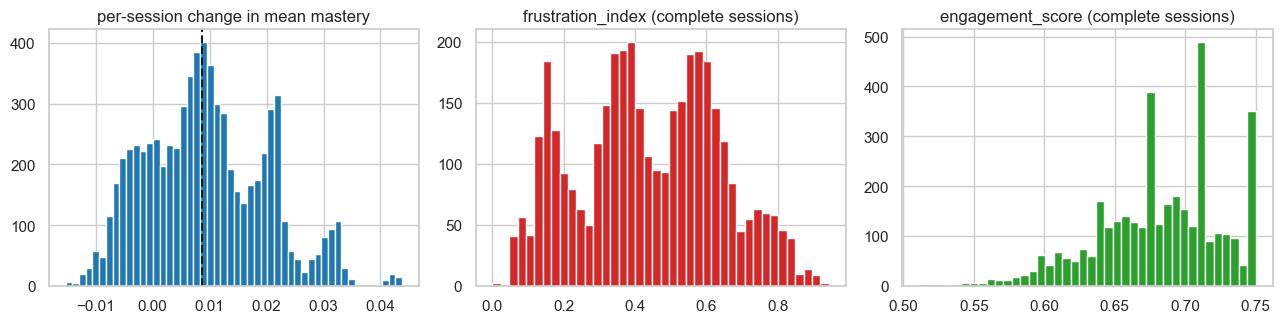

In [3]:
# quick check of the rule's action mix in the n300 policy decisions (streamed once)
from collections import Counter
sel, app, ovr, rec, stop, n = Counter(), Counter(), 0, 0, 0, 0
for line in open(cfg.N300_TABLES["policy_decisions"], encoding="utf-8"):
    r = json.loads(line); n += 1
    sel[r["selected_action"]] += 1; app[r["applied_action"]] += 1; ovr += r["action_overridden"]
    reason = r["safety_reason"] or ""
    rec += ("consecutive_error_safety_trigger" in reason) or ("rolling_strain_safety_trigger" in reason)
    stop += "safe_session_termination_requested" in reason
assert n == 59616, n
mix = pd.DataFrame({"selected": pd.Series(sel), "applied": pd.Series(app)}).reindex(["hold", "decrease_difficulty", "increase_difficulty"])
mix = (mix / n * 100).round(2)
display(mix); save_table(mix.reset_index(), "rule_action_mix_n300")
print(f"decisions={n}  override rate={ovr/n:.3%}  recovery-flag events={rec} ({rec/n:.3%})  safe-termination requests={stop} ({stop/n:.3%})")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(dm, bins=50, color="tab:blue"); ax[0].axvline(DATA_MEDIAN, color="k", ls="--"); ax[0].set_title("per-session change in mean mastery")
ax[1].hist(comp.fi, bins=40, color="tab:red"); ax[1].set_title("frustration_index (complete sessions)")
ax[2].hist(comp.es, bins=40, color="tab:green"); ax[2].set_title("engagement_score (complete sessions)")
fig.tight_layout(); save_fig(fig, "data_look"); plt.show()

### Findings — step 1


- **Mastery change per session** (change in the mean of the 7 skills, n = 7,200): **median 0.00863, IQR [0.00113, 0.01705]**, mean 0.00936; 21.7% of sessions are negative. Only 21.9% of individual skill-sessions change at all; among those the median step is 0.0558 (IQR 0.0064–0.0746). Mean-7 mastery climbs 0.166 → 0.217 (session 5) → 0.265 (10) → 0.391 (25).
- **Session-1 profile** (300 learners): mean-7 **0.166** (median 0.165, range 0.156–0.189). Counting 0.201, number_sense 0.182, division 0.171, multiplication 0.162; place_value, addition and subtraction sit at the 0.150 floor for every learner. Children start low *and almost identical*; this limits how much the dataset-resampled profiles can vary.
- **Frustration / engagement** (only the 3,761 sessions with `complete` telemetry — 50.1% of sessions; 31.6% are `technical_issue`, 18.3% `insufficient_evidence`): frustration_index mean 0.439, sd 0.199, median 0.429, 10–90% = 0.153–0.696; engagement_score mean 0.682, sd 0.045, range 0.511–0.750 (narrow). learner_state: 65.9% overloaded, 22.4% engaged, 11.6% productive_struggle.
- **Rule policy action mix** (59,616 decisions, n300): selected 43.79 / 27.01 / 29.21 % hold / decrease / increase; **applied 84.90 / 8.80 / 6.29 %** — this confirms the master plan's ≈ 85 / 9 / 6. Override rate **41.89 %** (≈ 42 % as cited). Real safety events are much rarer: recovery-flag triggers 2,693 (**4.52 %**) and safe-termination requests 103 (**0.173 %**). So over 90% of the overrides are caps/clamps, which is why the reward's safety term uses only the recovery flag / safe-stop.

## 2. Sanity check — the environment reproduces `run_c_session`

With both additions **off**, the rule policy run through `DifficultyEnv` must give the same selected / applied actions, difficulties, safety reasons,
task outcomes, overrides and session learner-state as the generator's own `run_c_session`. 10 seeds × 3 setups (combined mastery-driven,
combined familiarization, c_only). The same check is `tests/test_env.py`.

In [4]:
import test_env as T
key = lambda d: (d.selected_action, d.applied_action, d.action_overridden, d.safety_reason, d.difficulty_before, d.difficulty_after)
rows = []
for phase, mode in [("mastery_driven", "combined"), ("familiarization", "combined"), ("c_only", "c_only")]:
    n_dec = n_same = n_tasks = 0
    for seed in range(10):
        L = sample_learner(seed)
        env = T.play(DifficultyEnv(L, 3, phase, E.SeedManager(seed), session_mode=mode, sim=SimConfig(False, False)))
        ref = T.reference(L, seed, 3, phase, mode).record
        a, b = [key(d) for d in env.decisions], [key(d) for d in ref.adaptation_decisions]
        assert a == b, (phase, seed)
        assert [t.difficulty_level for t in env.tasks] == [t.difficulty_level for t in ref.task_instances]
        assert [s.terminal_reason for s in env.summaries] == [s.terminal_reason for s in ref.summaries]
        res = env.session_result()
        assert res["learner_state"] == ref.learner_state and res["safety_override_count"] == ref.safety_override_count
        n_dec += len(a); n_same += sum(x == y for x, y in zip(a, b)); n_tasks += len(env.tasks)
    rows.append(dict(setup=f"{mode}/{phase}", seeds=10, decisions=n_dec, identical=n_same, tasks=n_tasks))
P = pd.DataFrame(rows); display(P); save_table(P, "parity_check")
print("ALL IDENTICAL:", bool((P.decisions == P.identical).all()))

,setup,seeds,decisions,identical,tasks
0,combined/mastery_driven,10,120,120,120
1,combined/familiarization,10,120,120,120
2,c_only/c_only,10,120,120,120


ALL IDENTICAL: True


### Findings — step 2


- With both additions **off**, `DifficultyEnv` + the rule policy reproduces `run_c_session` **exactly** on every compared decision: combined/mastery_driven 120 / 120, combined/familiarization 120 / 120, c_only 120 / 120 (10 seeds each; **360 / 360** decisions identical in selected action, applied action, override flag, safety reason, difficulty before/after). Task difficulties, terminal reasons, safety-override count and the session learner_state also match (asserted).
- *Re-run note (after the NB02 env fixes, new learner sampling):* the 10 mastery-driven seeds now contain no safe-stop session (120 tasks for 120 decisions; before: 110 tasks for 109 decisions with one safe stop). The same assertions are in `tests/test_env.py` (full suite: 20 passed).
- Two extra tests lock in the additions' isolation: growth changes mastery only *between* sessions (the session's tasks are identical with growth on), and boredom dropout uses its own RNG (the tasks played before a dropout are identical to the no-dropout run).

## 3. Pick eta

Rule policy, mastery growth ON, boredom dropout OFF (the dataset has no dropout), 100 sampled learners × 25 sessions per value of eta.
Metric = per-session change in the mean of the 7 skills' mastery — the same quantity as in step 1. Choose the eta whose simulated **median** is closest to the
dataset median.

In [5]:
LEARNERS = [sample_learner(100 + i) for i in range(100)]
def cohort(policy, sim, n_sessions, seeds=range(100)):
    ds, ss = [], []
    for i in seeds:
        d, s = run_learner(policy, LEARNERS[i], n_sessions=n_sessions, seed=100 + i, sim=sim)
        ds.append(d.assign(learner=i)); ss.append(s.assign(learner=i))
    return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)

rows = []
for eta in (0.01, 0.02, 0.04, 0.08):
    _, S = cohort(rule_policy, SimConfig(growth=True, boredom=False, eta=eta), 25)
    g = S.mastery_gain
    rows.append(dict(eta=eta, sim_median=g.median(), sim_q25=g.quantile(.25), sim_q75=g.quantile(.75), abs_diff_to_data_median=abs(g.median() - DATA_MEDIAN), sessions=len(g)))
ET = pd.DataFrame(rows)
display(ET.round(5)); save_table(ET, "eta_table")
chosen = float(ET.loc[ET.abs_diff_to_data_median.idxmin(), "eta"])
print(f"dataset median = {DATA_MEDIAN:.5f}; chosen eta = {chosen}; rl_core.env.ETA = {E.ETA}")
assert chosen == E.ETA, "update ETA in rl_core/env.py to the chosen value"

,eta,sim_median,sim_q25,sim_q75,abs_diff_to_data_median,sessions
0,0.01,0.00319,0.00200,0.00483,0.00544,2500
1,0.02,0.00491,0.00312,0.00740,0.00372,2500
2,0.04,0.00740,0.00473,0.01140,0.00123,2500
3,0.08,0.01370,0.00790,0.01877,0.00507,2500


dataset median = 0.00863; chosen eta = 0.04; rl_core.env.ETA = 0.04


### Findings — step 3


Dataset median per-session change = **0.00863**. Simulated (rule policy, growth on, dropout off, 100 learners × 25 sessions = 2,500 sessions per row):

| eta | sim median | sim IQR | \|diff to data median\| |
|---|---|---|---|
| 0.01 | 0.00319 | 0.00200–0.00483 | 0.00544 |
| 0.02 | 0.00491 | 0.00312–0.00740 | 0.00372 |
| **0.04** | **0.00740** | 0.00473–0.01140 | **0.00123** |
| 0.08 | 0.01370 | 0.00790–0.01877 | 0.00507 |

**Chosen eta = 0.04** (now `rl_core.env.ETA`, asserted equal to the table's winner). It brackets the data median between 0.02 and 0.08 and gives a median 0.0012 *below* it (re-run with the NB02 env: varied starting mastery and the new dropout; before it was 0.0010 above); the simulated IQR (0.0047–0.0114) is narrower at the low end than the data's (0.0011–0.0171), because the dataset has near-zero and negative sessions that the simulator never produces (it only learns, never forgets). This is a median match, not a distribution match.

## 4. Does "always easy" still win?

100 learners × 10 sessions, three policies, **additions ON** (eta from step 3):
`level1` (go to level 1 and hold), `rule` (the generator's rule policy), `increase` (increase whenever safety allows).
Level 1 must no longer be best overall. For contrast the same policies are also run with the additions **OFF**.

C:\Users\Yasindu\AppData\Local\Temp\ipykernel_37084\112867648.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


additions ON (mean ± SE over 100 learners):


,mastery_gain,dropout_rate,first_try,mean_difficulty,frustration,safety_events,tasks_per_session
policy,,,,,,,
level1,0.0560 ± 0.0023,0.2630 ± 0.0161,0.7026 ± 0.0093,1.2666 ± 0.0097,0.2915 ± 0.0089,0.0790 ± 0.0190,10.8280 ± 0.0910
rule,0.1126 ± 0.0035,0.1450 ± 0.0136,0.6706 ± 0.0075,2.2112 ± 0.0447,0.3402 ± 0.0096,0.3000 ± 0.0385,11.2820 ± 0.0778
increase,0.0998 ± 0.0038,0.1350 ± 0.0128,0.6203 ± 0.0086,2.4994 ± 0.0467,0.3471 ± 0.0085,0.6890 ± 0.0652,11.2150 ± 0.0814


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_37084\112867648.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


additions OFF:


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_37084\112867648.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(ds, ignore_index=True), pd.concat(ss, ignore_index=True)


,mastery_gain,dropout_rate,first_try,mean_difficulty,frustration,safety_events,tasks_per_session
policy,,,,,,,
level1,0.0000 ± 0.0000,0.0000 ± 0.0000,0.6323 ± 0.0099,1.2370 ± 0.0076,0.3343 ± 0.0093,0.2080 ± 0.0360,11.9990 ± 0.0010
rule,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5893 ± 0.0087,1.8930 ± 0.0424,0.4260 ± 0.0109,0.4760 ± 0.0544,11.9800 ± 0.0099
increase,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5487 ± 0.0091,2.2518 ± 0.0454,0.3999 ± 0.0101,1.0400 ± 0.0781,11.8200 ± 0.0318


paired differences vs rule (additions ON, ± SE):


,mastery_gain,dropout_rate,first_try
level1 - rule,-0.0566 ± 0.0017,+0.1180 ± 0.0109,+0.0320 ± 0.0041
increase - rule,-0.0128 ± 0.0017,-0.0100 ± 0.0070,-0.0503 ± 0.0046


best on mastery gain: rule | lowest dropout: increase | best first-try success: level1
level 1 still best overall? -> False


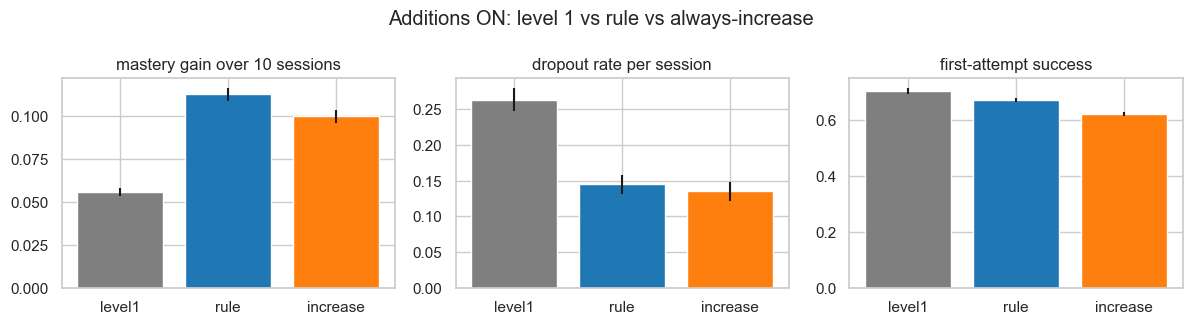

In [6]:
POL = {"level1": level1_policy, "rule": rule_policy, "increase": increase_policy}
def compare(sim):
    out = {}
    for name, pol in POL.items():
        _, S = cohort(pol, sim, 10)
        g = S.groupby("learner")
        out[name] = pd.DataFrame({
            "mastery_gain": g.apply(lambda x: x.mastery_end.iloc[-1] - x.mastery_start.iloc[0], include_groups=False),
            "dropout_rate": g.dropout.mean(), "first_try": g.first_try_rate.mean(),
            "mean_difficulty": g.mean_difficulty.mean(), "frustration": g.frustration_index.mean(),
            "safety_events": g.safety_override_count.mean(), "tasks_per_session": g.tasks.mean()})
    return out
def table(res):
    rows = []
    for name, df in res.items():
        rows.append({"policy": name, **{c: f"{df[c].mean():.4f} ± {df[c].std() / np.sqrt(df[c].count()):.4f}" for c in df.columns}})
    return pd.DataFrame(rows).set_index("policy")

ON = compare(SimConfig(growth=True, boredom=True, eta=E.ETA))
print("additions ON (mean ± SE over 100 learners):"); display(table(ON)); save_table(table(ON).reset_index(), "always_easy_on")
OFF = compare(SimConfig(growth=False, boredom=False))
print("additions OFF:"); display(table(OFF)); save_table(table(OFF).reset_index(), "always_easy_off")

pair = pd.DataFrame({m: {f"{a} - rule": f"{(ON[a][m] - ON['rule'][m]).mean():+.4f} ± {(ON[a][m] - ON['rule'][m]).std() / 10:.4f}" for a in ("level1", "increase")}
                     for m in ("mastery_gain", "dropout_rate", "first_try")})
print("paired differences vs rule (additions ON, ± SE):"); display(pair); save_table(pair.reset_index(), "always_easy_paired")

m = {k: {c: ON[k][c].mean() for c in ON[k].columns} for k in ON}
best_gain = max(m, key=lambda k: m[k]["mastery_gain"]); best_drop = min(m, key=lambda k: m[k]["dropout_rate"]); best_ft = max(m, key=lambda k: m[k]["first_try"])
print(f"best on mastery gain: {best_gain} | lowest dropout: {best_drop} | best first-try success: {best_ft}")
LEVEL1_STILL_BEST = (best_gain == "level1") or (best_drop == "level1")
print("level 1 still best overall? ->", LEVEL1_STILL_BEST)
assert not LEVEL1_STILL_BEST, "STOP: level 1 still wins with the additions on"

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, (c, t) in zip(ax, [("mastery_gain", "mastery gain over 10 sessions"), ("dropout_rate", "dropout rate per session"), ("first_try", "first-attempt success")]):
    vals = [ON[k][c].mean() for k in POL]; err = [ON[k][c].std() / 10 for k in POL]
    a.bar(list(POL), vals, yerr=err, color=["tab:gray", "tab:blue", "tab:orange"]); a.set_title(t)
fig.suptitle("Additions ON: level 1 vs rule vs always-increase"); fig.tight_layout(); save_fig(fig, "always_easy"); plt.show()

### Findings — step 4


100 learners × 10 sessions, additions **ON** (eta 0.04), mean ± SE across learners:

| policy | mastery gain | dropout / session | first-try success | mean difficulty | frustration | safety events / session |
|---|---|---|---|---|---|---|
| level1 | 0.0560 ± 0.0023 | **0.263 ± 0.016** | **0.703 ± 0.009** | 1.27 | 0.292 | 0.079 |
| rule | **0.1126 ± 0.0035** | 0.145 ± 0.014 | 0.671 ± 0.008 | 2.21 | 0.340 | 0.300 |
| increase | 0.0998 ± 0.0038 | 0.135 ± 0.013 | 0.620 ± 0.009 | 2.50 | 0.347 | 0.689 |

- **Level 1 is no longer best overall.** It has the *lowest* mastery gain (paired −0.0566 ± 0.0017 vs rule, i.e. about half) and the *highest* dropout (paired +0.118 ± 0.011 — boredom dropout does what it was meant to). It still wins on first-try success (+0.032 ± 0.004), frustration and safety events, which are exactly the "comfort" metrics. The check passes (`assert`), so no stop.
- **Rule vs always-increase:** mastery gain −0.0128 ± 0.0017 and dropout −0.010 ± 0.007 for increase vs rule, first-try −0.050 ± 0.005, and safety events are about 2.3× (0.69 vs 0.30). The rule is now clearly ahead of always-increase on mastery gain as well as on comfort.
- **Contrast, additions OFF:** mastery gain and dropout are 0 for every policy, so only comfort metrics differ and level 1 wins them all (first-try 0.632 vs 0.589 / 0.549, frustration 0.334 vs 0.426 / 0.400, safety events 0.21 vs 0.48 / 1.04). That is the "always easy" problem the additions fix.
- **Caveats to know.** After the NB02 fixes dropout is moderate (the rule ends 14.5 % of sessions early; 10.8–11.3 tasks played of 12) instead of 36–51 %. First-try success is 0.62–0.70 for every policy, still below the old 0.775 target, which NB02 replaced by a simulator-derived tau = 0.70.
- *This step was re-run after the NB02 env changes (dropout DROP_A −5.2 / DROP_C 1.0, learners drawn from a random session 1–25); the numbers above are the new ones.*

## 5. What NB02 will use

In [7]:
d, s = run_learner(rule_policy, LEARNERS[0], n_sessions=3, seed=100, sim=SimConfig(True, True, E.ETA))
print("run_learner returns two tidy frames. decisions columns:\n ", list(d.columns))
print("sessions columns:\n ", list(s.columns))
print("\nobservation keys:", list(DifficultyEnv(LEARNERS[0], 3, "mastery_driven", E.SeedManager(1)).reset().keys()))
print("constants (all ASSUMPTION):", dict(ETA=E.ETA, GROWTH_DELTA=E.GROWTH_DELTA, GROWTH_SIGMA=E.GROWTH_SIGMA, ETA_WRONG_DIV=E.ETA_WRONG_DIV,
      BORED_MARGIN=E.BORED_MARGIN, dropout=(E.DROP_A, E.DROP_B, E.DROP_C)))

run_learner returns two tidy frames. decisions columns:
  ['session', 'phase', 'difficulty', 'first_try', 'strain', 'mastery', 'tasks_done', 'allowed', 'action', 'boredom_run', 'applied_action', 'action_overridden', 'activate_recovery_flag', 'request_safe_termination', 'difficulty_after', 'dropout', 'next_first_try', 'next_attempts', 'next_completed']
sessions columns:
  ['session', 'phase', 'tasks', 'dropout', 'safe_stop', 'telemetry', 'frustration_index', 'engagement_score', 'learner_state', 'safety_override_count', 'first_try_rate', 'mean_difficulty', 'mastery_start', 'mastery_end', 'mastery_gain', 'skills']

observation keys: ['difficulty', 'first_try', 'strain', 'mastery', 'tasks_done']
constants (all ASSUMPTION): {'ETA': 0.04, 'GROWTH_DELTA': 0.1, 'GROWTH_SIGMA': 0.15, 'ETA_WRONG_DIV': 4, 'BORED_MARGIN': 0.15, 'dropout': (-5.2, 0.6, 1.0)}


### Findings — step 5


- **From `rl_core.env`:** `sample_learner(seed)`, `DifficultyEnv(learner, session_no, phase, SeedManager, ...)` with `reset() → obs`, `allowed_actions()`, `step(action) → (obs, info, done)`, and `run_learner(policy_fn, learner, n_sessions, max_tasks, seed, sim)` returning `(decisions_df, sessions_df)`. `policy_fn(obs, allowed, env) → action`; familiarization sessions always use the rule policy. Reference policies: `rule_policy`, `level1_policy`, `increase_policy`.
- **Observation** has exactly 5 keys: `difficulty`, `first_try` (last-5 first-attempt success; 0.5 before any attempt), `strain`, `mastery` (session-start, selected skill), `tasks_done`. The last decision of a session has no next task (`next_summary=None`, `done=True`); a dropout ends the session after the played task, before the next decision.
- **Decision frame columns** include obs, `allowed`, `action`, `applied_action`, `activate_recovery_flag`, `request_safe_termination`, `dropout`, `next_first_try`, `next_attempts`, `next_completed`; the **session frame** has `frustration_index`, `engagement_score`, `learner_state`, `dropout`, `safe_stop`, mastery start/end/gain.
- **Constants (all ASSUMPTION, switchable via `SimConfig(growth, boredom, eta)`):** eta 0.04 (fitted here), stretch offset 0.10, width 0.15, wrong-answer factor 1/4, boredom margin 0.15, dropout logit −5.2 + 0.6·run + 1.0·strain (changed in NB02). Growth is computed on a latent mastery that is carried to the next session; within a session the generator and the boredom test use the session-start value.
- **Speed:** ≈ 0.012 s per simulated session (2,500 sessions ≈ 30 s), so tens of thousands of training sessions are cheap. Nothing here uses population, traits or learner type as an agent input.
- **Learner sampling (changed in NB02):** grade and the starting 7-skill mastery come from a random session (1–25) of a random dataset learner; traits and `session_context_c` are uniform draws (the dataset stores none) — an assumption, and starting mastery now spans about 0.16–0.51 (mean-7), whereas session-1 profiles alone were nearly identical (see step 1).

---
_Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children._